# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: `GSAF5.xls`).

1. Open the shark attack file using Pandas. It is probably not a csv file, so `read_csv` won't work.
2. Drop any columns that do not contain data.
3. Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
4. Clean the Age variable and make a histogram of the ages of the victims.
5. What proportion of victims are male?
6. Clean the `Type` variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Yafet Getachew

**Date:** 9/2/26

#Question 1.1
###Choices I made include...
- First I read the file and printed the headers and their corresponding datatypes to understand the data better
- From there, I realized that the price values were stored as objects instead of integers, meaning to_numeric would fail since a comma is added once the price exceeded 999
- I then changed it so any numbers with a comma were stripped of the comma to then be translated to integers after i changed the type
###Missing values
- No missing values before or after changes
#Question 1.2
- Proportion of the values are missing = 9848 out of 12925 - Is this a concern? Yes, as around ~76% of data being missing, any conclusion we come to will only represent ~24% of cases where injury was actually recorded, which may not be properly reflect/represent the rest.
- After cross-tabulating the cleaned subject_injury variable with the force_type variable I was able to discover that injury outcomes for more severe/rare cases like firearm, gun point display, and police k9 bite have much less missing data (~0-40%) as compared to everyday/more common force types like bodily force and taser which had ~75% of missing data.


In [64]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
url = 'https://raw.githubusercontent.com/YafetG3/A01-data-wrangling/main/data/airbnb_hw.csv'
df = pd.read_csv(url, low_memory=False)



print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')

df.head()

print("Missing values before:", df['Price'].isna().sum())

comma_prices = df[df['Price'].str.contains(',', na=False)]
print(comma_prices['Price'].head())

df['Price'] = df['Price'].str.replace(',', '', regex=False)
df['Price'] = df['Price'].astype('int64')

print("Missing values after:", df['Price'].isna().sum())

df.shape:
(30478, 13) 

df.dtypes:
Host Id                         int64
Host Since                     object
Name                           object
Neighbourhood                  object
Property Type                  object
Review Scores Rating (bin)    float64
Room Type                      object
Zipcode                       float64
Beds                          float64
Number of Records               int64
Number Of Reviews               int64
Price                          object
Review Scores Rating          float64
dtype: object 

Missing values before: 0
101     1,990
263     1,000
764     1,200
1272    1,000
1275    5,000
Name: Price, dtype: object
Missing values after: 0


In [77]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
url = 'https://raw.githubusercontent.com/YafetG3/A01-data-wrangling/main/data/mn_police_use_of_force.csv'
df = pd.read_csv(url, low_memory=False)



print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')


df.head()

proportion_missing = df['subject_injury'].isna().mean()
print(f"Proportion Missing: {proportion_missing:.2%}" '\n')

df['subject_injury_cleaned'] = df['subject_injury'].fillna('Missing')

ct_counts = pd.crosstab(df['force_type'], df['subject_injury_cleaned'])

print("--- Raw Incident Counts ---")
print(ct_counts)

df.shape:
(12925, 13) 

df.dtypes:
response_datetime     object
problem               object
is_911_call           object
primary_offense       object
subject_injury        object
force_type            object
force_type_action     object
race                  object
sex                   object
age                  float64
type_resistance       object
precinct               int64
neighborhood          object
dtype: object 

Missing Values: 9848 out of 12925
Proportion Missing: 76.19%

--- Raw Incident Counts ---
subject_injury_cleaned       Missing    No   Yes
force_type                                      
Baton                              2     0     2
Bodily Force                    7051  1093  1286
Chemical Irritant               1421   131    41
Firearm                            0     2     0
Gun Point Display                 27    33    44
Improvised Weapon                 74    34    40
Less Lethal                       87     0     0
Less Lethal Projectile             0     

#Question 2.1
- done
#Question 2.2
- done
#Question 2.3
- After cleaning year variable, values ranged from 0 to 2026. Then, filtering for years 1940+ showed that attacks per year have increased significantly over time especially from 1940s to the 2010s. Also, it should be pointed out that although the numbers for 2020s look lower, that decade only covers ~6–7 years so far
#Question 2.4
- done
#Question 2.5
- Proportion of male victims: 80.27%
#Question 2.6
- After clean the Type variable so it only takes three values: Provoked and Unprovoked and Unknown. The proportion of unprovoked attacks came out to: 73.95%

In [4]:
from google.colab import files
uploaded = files.upload()

Saving GSAF5.xls to GSAF5.xls


count    7115.000000
mean     1936.549122
std       269.943193
min         0.000000
25%      1948.000000
50%      1987.000000
75%      2010.000000
max      2026.000000
Name: Year, dtype: float64


--- After Filtering for on after 1940 ---
count    5581.000000
mean     1992.668518
std        24.311209
min      1940.000000
25%      1970.000000
50%      2000.000000
75%      2013.000000
max      2026.000000
Name: Year, dtype: float64
(7117, 23)

--- Proportion of male victims ---
Proportion male: 80.27%

--- Number of each type ---
Type_clean
Unprovoked    5263
Unknown       1205
Provoked       649
Name: count, dtype: int64

--- Proportion of unprovoked ---
Proportion unprovoked (of all records): 73.95%


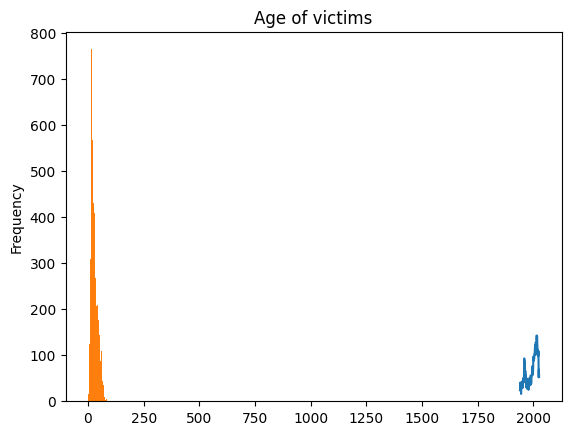

In [55]:
import pandas as pd

df = pd.read_excel('GSAF5.xls')

df_clean = df.drop(columns=['pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Unnamed: 21', 'Unnamed: 22'])

df_clean['Year'] = pd.to_numeric(df_clean['Year'], errors='coerce')
print(df_clean['Year'].describe())
print('\n')

print("--- After Filtering for on after 1940 ---")
latest = df_clean[df_clean['Year'] >= 1940]
print(latest['Year'].describe())

attacks_per_year = latest['Year'].value_counts().sort_index()
attacks_per_year.plot(kind='line', title='Shark Attacks per Year (1940+)')

print(df.shape)
df_clean.head()

df_clean['Age_clean'] = pd.to_numeric(df_clean['Age'], errors='coerce')

df_clean['Age_clean'].plot(kind='hist', bins=20, title='Age of victims')

df_clean['Sex'] = df_clean['Sex'].str.strip().str.upper()


print("\n--- Proportion of male victims ---")
prop_male = (df_clean['Sex'] == 'M').mean()
print(f"Proportion male: {prop_male:.2%}")

def clean_type(x):
    if pd.isna(x):
        return 'Unknown'
    s = str(x).strip().lower()
    if 'unprovoked' in s:
        return 'Unprovoked'
    elif 'provoked' in s:
        return 'Provoked'
    else:
        return 'Unknown'


print("\n--- Number of each type ---")
df_clean['Type_clean'] = df_clean['Type'].apply(clean_type)
print(df_clean['Type_clean'].value_counts())


print("\n--- Proportion of unprovoked ---")
prop_unprovoked = (df_clean['Type_clean'] == 'Unprovoked').mean()
print(f"Proportion unprovoked (of all records): {prop_unprovoked:.2%}")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]